# AssessAI: Evaluation and Validation

This notebook has two parts.

**Part 1 — Usage demo.** Runs all three AssessAI metrics (specificity, repetition, coverage) on the 100-question maintenance dataset. This is what a user of the toolkit sees.

**Part 2 — Validation study.** Compares eight specificity methods against 60 hand-labeled examples using Spearman correlation. This is the research contribution.

In [23]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.preprocessing import load_questions
from src.evaluation_metrics import Evaluator

maintenance_questions = load_questions(
    ROOT / "data" / "maintenance_questions.csv",
    column="Questions",
)
print(f"Loaded {len(maintenance_questions)} questions.")
print(f"Example: {maintenance_questions[0][:80]}...")

Loaded 100 questions.
Example: Does your organization have a formalized maintenance strategy aligned with Indus...


In [ ]:
sub_categories = [
    "Identification", "Reporting", "Execution",
    "Resource Management", "Planning", "Documentation",
]

ev = Evaluator()

spec = ev.specificity(maintenance_questions, method="rules")
rep  = ev.repetition(maintenance_questions)
cov  = ev.coverage(maintenance_questions, sub_categories)

print("=== Specificity (rules) ===")
print(f"  mean = {spec['mean']:.2f}   range = [{spec['min']:.1f}, {spec['max']:.1f}]")
print()

print("=== Repetition ===")
for k, v in rep.items():
    print(f"  {k:22s} {v}")

print()
print("=== Coverage ===")
print(f"  score    = {cov['score']:.3f}")
print(f"  presence = {cov['presence']:.3f}")
print(f"  balance  = {cov['balance']:.3f}")
print()
for b in cov["sub_categories"]:
    mark = "covered" if b["covered"] else "MISSING"
    print(f"  [{mark:7s}] {b['name']:<22} best_similarity = {b['similarity']:.3f}")

In [12]:
import sys
from pathlib import Path

# Make sure we can import from src/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from src.embeddings import Embedder
from src.evaluation_metrics import (
    SpecificityClassifier,
    _specificity_rules,
    _specificity_anchors,
    DEFAULT_SPECIFIC_ANCHORS,
    DEFAULT_VAGUE_ANCHORS,
    DEFAULT_STRETCH,
)

print("setup complete")
print("ROOT =", ROOT)

setup complete
ROOT = C:\Users\gaura\OneDrive\Desktop\New Beginnings\assessai-toolkit


In [13]:
gen = pd.read_csv(ROOT / "data" / "hand_scored_gen.csv")
sub = pd.read_csv(ROOT / "data" / "hand_scored_subcat.csv")

# Both files use a column named "Question" and "Specificity Score"
gen = gen.rename(columns={"Question": "question", "Specificity Score": "score"})
sub = sub.rename(columns={"Question": "question", "Specificity Score": "score"})

gen["source"] = "gen"
sub["source"] = "subcat"

df = pd.concat([gen[["question", "score", "source"]],
                sub[["question", "score", "source"]]],
               ignore_index=True)

df["question"] = df["question"].astype(str).str.strip()
df["score"] = df["score"].astype(int)

print(f"Loaded {len(df)} labeled questions")
print("Label distribution:")
print(df["score"].value_counts().sort_index())

Loaded 60 labeled questions
Label distribution:
score
1     1
2    21
3    21
4    17
Name: count, dtype: int64


In [14]:
print(df.groupby("source")["score"].describe())
print()
print("Minimum class count (determines fold count):")
print(df["score"].value_counts().min())

        count  mean       std  min  25%  50%  75%  max
source                                                
gen      30.0   2.8  0.761124  2.0  2.0  3.0  3.0  4.0
subcat   30.0   3.0  0.909718  1.0  2.0  3.0  4.0  4.0

Minimum class count (determines fold count):
1


In [15]:
questions = df["question"].tolist()
human = df["score"].values

rules_scores = _specificity_rules(questions)

rho_rules, p_rules = spearmanr(human, rules_scores)
print(f"Rules specificity: Spearman rho = {rho_rules:+.3f}  (p = {p_rules:.4f})")
print(f"  Rules range: [{rules_scores.min():.1f}, {rules_scores.max():.1f}], mean = {rules_scores.mean():.2f}")
print(f"  Human range: [{human.min()}, {human.max()}], mean = {human.mean():.2f}")

Rules specificity: Spearman rho = +0.019  (p = 0.8826)
  Rules range: [2.8, 4.5], mean = 3.49
  Human range: [1, 4], mean = 2.90


In [16]:
emb = Embedder()
anchor_scores = _specificity_anchors(
    questions, emb,
    DEFAULT_SPECIFIC_ANCHORS, DEFAULT_VAGUE_ANCHORS, DEFAULT_STRETCH,
)

rho_anchor, p_anchor = spearmanr(human, anchor_scores)
print(f"Anchors specificity: Spearman rho = {rho_anchor:+.3f}  (p = {p_anchor:.4f})")
print(f"  Anchors range: [{anchor_scores.min():.1f}, {anchor_scores.max():.1f}], mean = {anchor_scores.mean():.2f}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Anchors specificity: Spearman rho = +0.083  (p = 0.5270)
  Anchors range: [1.6, 5.0], mean = 3.32


In [17]:
from sklearn.model_selection import StratifiedKFold

# Drop the single class-1 example: cannot be part of any stratified fold.
df_clf = df[df["score"] >= 2].reset_index(drop=True)
y_clf = df_clf["score"].values
q_clf = df_clf["question"].tolist()

print(f"Rows for classifier comparison: {len(q_clf)}")
print(f"Class distribution: {dict(zip(*np.unique(y_clf, return_counts=True)))}")

feature_sets = ["tfidf", "sbert"]
model_names = ["logreg", "rf", "xgb"]

clf_results = []  # (label, rho, pvalue)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for feat in feature_sets:
    for mdl in model_names:
        preds = np.zeros(len(q_clf))
        for fold_i, (train_idx, test_idx) in enumerate(skf.split(q_clf, y_clf)):
            q_train = [q_clf[i] for i in train_idx]
            q_test  = [q_clf[i] for i in test_idx]
            y_train = y_clf[train_idx]

            clf = SpecificityClassifier(features=feat, model=mdl,
                                        embedder=emb, random_state=42)
            clf.fit(q_train, y_train)
            preds[test_idx] = clf.predict(q_test)

        rho, pval = spearmanr(y_clf, preds)
        label = f"{feat}+{mdl}"
        clf_results.append((label, rho, pval))
        print(f"{label:15s}  rho = {rho:+.3f}  (p = {pval:.4f})")

Rows for classifier comparison: 59
Class distribution: {np.int64(2): np.int64(21), np.int64(3): np.int64(21), np.int64(4): np.int64(17)}
tfidf+logreg     rho = -0.069  (p = 0.6015)
tfidf+rf         rho = +0.000  (p = 0.9988)
tfidf+xgb        rho = +0.109  (p = 0.4092)
sbert+logreg     rho = +0.342  (p = 0.0080)
sbert+rf         rho = +0.145  (p = 0.2725)
sbert+xgb        rho = +0.168  (p = 0.2028)


In [18]:
all_results = [
    ("rules",        rho_rules,  p_rules),
    ("anchors",      rho_anchor, p_anchor),
] + clf_results

summary = pd.DataFrame(all_results, columns=["method", "spearman_rho", "p_value"])
summary = summary.sort_values("spearman_rho", ascending=False).reset_index(drop=True)
summary["significant_p05"] = summary["p_value"] < 0.05
summary

,method,spearman_rho,p_value,significant_p05
0,sbert+logreg,0.342130,0.007995,True
1,sbert+xgb,0.168223,0.202808,False
2,sbert+rf,0.145220,0.272459,False
3,tfidf+xgb,0.109474,0.409155,False
4,anchors,0.083274,0.527017,False
5,rules,0.019478,0.882569,False
6,tfidf+rf,0.000203,0.998782,False
7,tfidf+logreg,-0.069397,0.601480,False


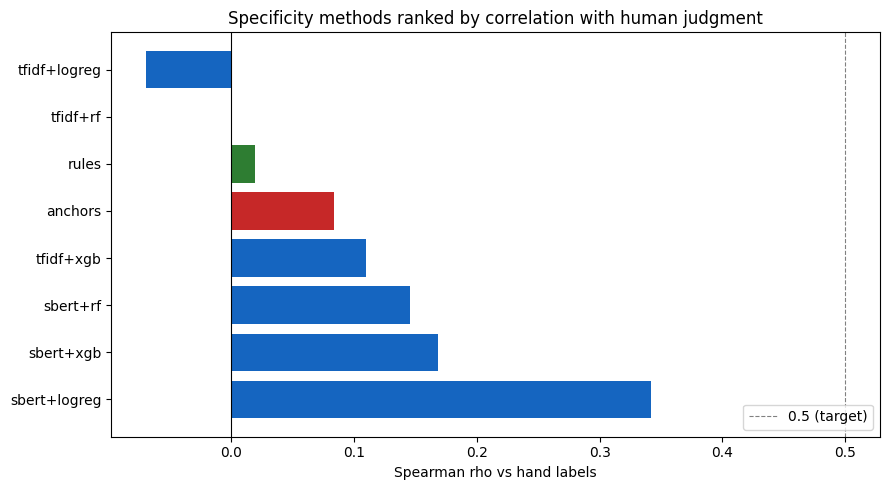

Saved: C:\Users\gaura\OneDrive\Desktop\New Beginnings\assessai-toolkit\docs\validation.png


In [19]:
docs = ROOT / "docs"
docs.mkdir(exist_ok=True)

plt.figure(figsize=(9, 5))
colors = []
for m in summary["method"]:
    if m == "rules":
        colors.append("#2e7d32")          # green
    elif m == "anchors":
        colors.append("#c62828")          # red
    else:
        colors.append("#1565c0")          # blue

bars = plt.barh(summary["method"], summary["spearman_rho"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.axvline(0.5, color="grey", linestyle="--", linewidth=0.8, label="0.5 (target)")
plt.xlabel("Spearman rho vs hand labels")
plt.title("Specificity methods ranked by correlation with human judgment")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(docs / "validation.png", dpi=120, bbox_inches="tight")
plt.show()

print("Saved:", docs / "validation.png")

In [20]:
summary.to_csv(ROOT / "docs" / "validation_results.csv", index=False)
print(summary.to_string(index=False))

      method  spearman_rho  p_value  significant_p05
sbert+logreg      0.342130 0.007995             True
   sbert+xgb      0.168223 0.202808            False
    sbert+rf      0.145220 0.272459            False
   tfidf+xgb      0.109474 0.409155            False
     anchors      0.083274 0.527017            False
       rules      0.019478 0.882569            False
    tfidf+rf      0.000203 0.998782            False
tfidf+logreg     -0.069397 0.601480            False
